# Credit Card Default Prediction

This project builds a classification model to predict whether a customer
will default on their credit card payment in the following month.

The dataset contains information about 30,000 credit card customers from
Taiwan, including credit limits, demographic details, repayment history,
bill amounts and previous payments.

Source: UCI Machine Learning Repository

In [1]:
# Import useful libraries used in the entire project
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Mac-specific certificate setup
import ssl
import urllib.request
import certifi

ssl_context = ssl.create_default_context(cafile=certifi.where())

https_handler = urllib.request.HTTPSHandler(context=ssl_context)
opener = urllib.request.build_opener(https_handler)

urllib.request.install_opener(opener)

In [3]:
# Importing Data
from ucimlrepo import fetch_ucirepo 

default_cc_clients = fetch_ucirepo(id=350)

In [4]:
# Load data
X = default_cc_clients.data.features.copy()
y = default_cc_clients.data.targets.copy()

cc_dataset = pd.concat([X,y], axis=1)

# Rename columns using meaningful names
column_names = {
    "X1": "credit_limit_ntd",
    "X2": "gender",
    "X3": "education_level",
    "X4": "marital_status",
    "X5": "age",

    "X6": "repayment_status_sep",
    "X7": "repayment_status_aug",
    "X8": "repayment_status_jul",
    "X9": "repayment_status_jun",
    "X10": "repayment_status_may",
    "X11": "repayment_status_apr",

    "X12": "bill_amount_sep_ntd",
    "X13": "bill_amount_aug_ntd",
    "X14": "bill_amount_jul_ntd",
    "X15": "bill_amount_jun_ntd",
    "X16": "bill_amount_may_ntd",
    "X17": "bill_amount_apr_ntd",

    "X18": "payment_amount_sep_ntd",
    "X19": "payment_amount_aug_ntd",
    "X20": "payment_amount_jul_ntd",
    "X21": "payment_amount_jun_ntd",
    "X22": "payment_amount_may_ntd",
    "X23": "payment_amount_apr_ntd",

    "Y": "default_payment_next_month"
}

cc_dataset = cc_dataset.rename(columns=column_names)

cc_dataset.head()

,credit_limit_ntd,gender,education_level,marital_status,age,repayment_status_sep,repayment_status_aug,repayment_status_jul,repayment_status_jun,repayment_status_may,...,bill_amount_jun_ntd,bill_amount_may_ntd,bill_amount_apr_ntd,payment_amount_sep_ntd,payment_amount_aug_ntd,payment_amount_jul_ntd,payment_amount_jun_ntd,payment_amount_may_ntd,payment_amount_apr_ntd,default_payment_next_month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [5]:
cc_dataset.tail()

,credit_limit_ntd,gender,education_level,marital_status,age,repayment_status_sep,repayment_status_aug,repayment_status_jul,repayment_status_jun,repayment_status_may,...,bill_amount_jun_ntd,bill_amount_may_ntd,bill_amount_apr_ntd,payment_amount_sep_ntd,payment_amount_aug_ntd,payment_amount_jul_ntd,payment_amount_jun_ntd,payment_amount_may_ntd,payment_amount_apr_ntd,default_payment_next_month
29995,220000,1,3,1,39,0,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,150000,1,3,2,43,-1,-1,-1,-1,0,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,30000,1,2,2,37,4,3,2,-1,0,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,80000,1,3,1,41,1,-1,0,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1
29999,50000,1,2,1,46,0,0,0,0,0,...,36535,32428,15313,2078,1800,1430,1000,1000,1000,1


In [6]:
cc_dataset.sample(10, random_state=42)

,credit_limit_ntd,gender,education_level,marital_status,age,repayment_status_sep,repayment_status_aug,repayment_status_jul,repayment_status_jun,repayment_status_may,...,bill_amount_jun_ntd,bill_amount_may_ntd,bill_amount_apr_ntd,payment_amount_sep_ntd,payment_amount_aug_ntd,payment_amount_jul_ntd,payment_amount_jun_ntd,payment_amount_may_ntd,payment_amount_apr_ntd,default_payment_next_month
2308,30000,1,2,2,25,0,0,0,0,0,...,12580,13716,14828,1500,2000,1500,1500,1500,2000,0
22404,150000,2,1,2,26,0,0,0,0,0,...,101581,77741,77264,4486,4235,3161,2647,2669,2669,0
23397,70000,2,3,1,32,0,0,0,0,0,...,69753,70111,70212,2431,3112,3000,2438,2500,2554,0
25058,130000,1,3,2,49,0,0,0,0,0,...,16898,11236,6944,1610,1808,7014,27,7011,4408,0
2664,50000,2,2,2,36,0,0,0,0,0,...,19574,20295,19439,2000,1500,1000,1800,0,1000,1
8511,50000,2,2,2,29,-1,-1,-1,0,0,...,11512,8490,0,801,11512,0,0,0,950,0
5148,110000,1,3,2,33,1,2,0,0,0,...,2625,0,0,0,1000,0,0,0,0,1
7790,140000,2,1,1,32,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
11311,260000,2,2,3,38,-1,-1,-1,-1,-1,...,8000,24406,18043,8000,8000,8000,24406,2000,389,0
19043,80000,2,2,2,23,0,0,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0


In [7]:
cc_dataset.shape

(30000, 24)

In [8]:
schema = pd.DataFrame(
    {
        "dtype":cc_dataset.dtypes,
        "non-null":cc_dataset.notna().sum(),
        "missing":cc_dataset.isna().sum(),
        "missing_pct":cc_dataset.isna().mean()*100,
        "unique_values":cc_dataset.nunique(dropna=False),
    }
).sort_values("missing_pct", ascending=False)
schema

,dtype,non-null,missing,missing_pct,unique_values
credit_limit_ntd,int64,30000,0,0.0,81
gender,int64,30000,0,0.0,2
payment_amount_apr_ntd,int64,30000,0,0.0,6939
payment_amount_may_ntd,int64,30000,0,0.0,6897
payment_amount_jun_ntd,int64,30000,0,0.0,6937
payment_amount_jul_ntd,int64,30000,0,0.0,7518
payment_amount_aug_ntd,int64,30000,0,0.0,7899
payment_amount_sep_ntd,int64,30000,0,0.0,7943
bill_amount_apr_ntd,int64,30000,0,0.0,20604
bill_amount_may_ntd,int64,30000,0,0.0,21010


In [9]:
duplicate_rows = cc_dataset.duplicated().sum()

print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 35


In [10]:
cc_dataset.drop(columns=['gender','education_level','marital_status']).describe().T 
#gender','education_level','marital_status these are considered as categorical variables and will study separately

,count,mean,std,min,25%,50%,75%,max
credit_limit_ntd,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
age,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
repayment_status_sep,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
repayment_status_aug,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
repayment_status_jul,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
repayment_status_jun,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
repayment_status_may,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0
repayment_status_apr,30000.0,-0.291100,1.149988,-2.0,-1.00,0.0,0.00,8.0
bill_amount_sep_ntd,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.00,964511.0
bill_amount_aug_ntd,30000.0,49179.075167,71173.768783,-69777.0,2984.75,21200.0,64006.25,983931.0


#### Explore Target Variable

In [11]:
target = "default_payment_next_month"
counts_target = cc_dataset[target].value_counts()
pct = cc_dataset[target].value_counts(normalize=True).mul(100).round(2).astype(str).add('%')

summary = (counts_target.astype(str) + ' ' + pct).rename(index={0:'No default', 1: 'Default in the following month'})
print(f"Class Distribution\n{summary}")

Class Distribution
default_payment_next_month
No default                        23364 77.88%
Default in the following month     6636 22.12%
dtype: str


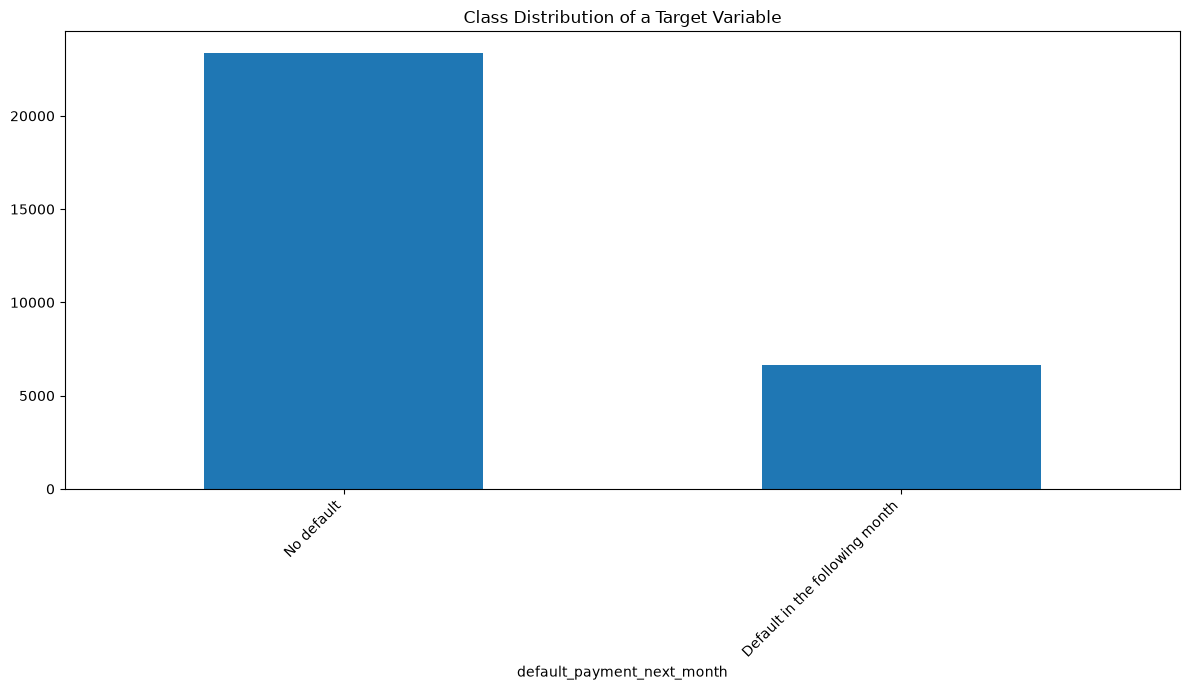

In [12]:
ax = counts_target.rename(index={0: 'No default', 1: 'Default in the following month'}) \
           .plot(kind='bar', figsize=(12, 7))
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_title('Class Distribution of a Target Variable')
plt.tight_layout()
plt.show()


In [13]:
category_columns = ["gender", "education_level", "marital_status"]

category_mappings = {
    "gender": {
        1: "Male",
        2: "Female"
    },
    "education_level": {
        1: "Graduate School",
        2: "University",
        3: "High School",
        4: "Others"
    },
    "marital_status": {
        1: "Married",
        2: "Single",
        3: "Others"
    }
}

category_tables = []

for column in category_columns:
    codes = sorted(cc_dataset[column].dropna().unique())

    table = pd.DataFrame({
        "column": column,
        "code": codes
    })

    table["meaning"] = (
        table["code"]
        .map(category_mappings[column])
        .fillna("Undocumented / Unknown")
    )

    category_tables.append(table)

category_table = pd.concat(category_tables, ignore_index=True)

category_table

,column,code,meaning
0,gender,1,Male
1,gender,2,Female
2,education_level,0,Undocumented / Unknown
3,education_level,1,Graduate School
4,education_level,2,University
5,education_level,3,High School
6,education_level,4,Others
7,education_level,5,Undocumented / Unknown
8,education_level,6,Undocumented / Unknown
9,marital_status,0,Undocumented / Unknown


### Findings from categorical variables

- `gender` contains only the documented codes 1 and 2.
- `education_level` contains documented codes 1–4, along with undocumented codes 0, 5 and 6.
- `marital_status` contains documented codes 1–3, along with undocumented code 0.
- The undocumented values will temporarily be treated as "Undocumented / Unknown". No values will be removed or replaced without further analysis.

In [14]:
# How many customers and what percentage of customers belong to each code in gender, education_level, and marital_status?
category_tables = []

for column in category_columns:
    counts = cc_dataset[column].value_counts(dropna=False)
    pct = cc_dataset[column].value_counts(normalize=True).mul(100).round(2)

    table = pd.DataFrame({
        "column": column,
        "code": counts.index,
        "count": counts.values,
        "percentage": pct.values
    })
    table["meaning"] = (
        table["code"]
        .map(category_mappings[column])
        .fillna("Undocumented / Unknown")
    )
    category_tables.append(table)

category_summary = pd.concat(category_tables, ignore_index=True)
category_summary

,column,code,count,percentage,meaning
0,gender,2,18112,60.37,Female
1,gender,1,11888,39.63,Male
2,education_level,2,14030,46.77,University
3,education_level,1,10585,35.28,Graduate School
4,education_level,3,4917,16.39,High School
5,education_level,5,280,0.93,Undocumented / Unknown
6,education_level,4,123,0.41,Others
7,education_level,6,51,0.17,Undocumented / Unknown
8,education_level,0,14,0.05,Undocumented / Unknown
9,marital_status,2,15964,53.21,Single


# From the above following question can be answered
- Which category has the highest percentage in each column?
  - Gender: Female with 60.37%
  - Education Level: University 46.77%
  - Marital Status: Single is at 53.21%
- What total percentage of education_level is undocumented (0, 5, and 6 combined)? 1.15%
- Is the undocumented percentage large enough to seriously affect the analysis? 1.15% is not large enough but we should analyse whether it may impact the output.
- Based on these results, would you keep the undocumented values as a separate category or remove those records? I would keep them until further analysis.

#### Do customers with undocumented education codes have a noticeably different default rate compared with the documented education groups?

In [15]:
cc_dataset.groupby("education_level")["default_payment_next_month"].value_counts(normalize=True).mul(100).round(2)

education_level  default_payment_next_month
0                0                             100.00
1                0                              80.77
                 1                              19.23
2                0                              76.27
                 1                              23.73
3                0                              74.84
                 1                              25.16
4                0                              94.31
                 1                               5.69
5                0                              93.57
                 1                               6.43
6                0                              84.31
                 1                              15.69
Name: proportion, dtype: float64

In [16]:
cc_dataset["education_level"].value_counts().sort_index()

education_level
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

# From the above following question can be answered
- Which documented education group has the highest default rate? Education Level documented - High School has highest default rate of 25.16%
- What are the default rates for undocumented codes 0, 5, and 6? Education level undocumented - For 0: 0.00%, for 5: 6.43% and for 6: 15.69%
- Are these undocumented groups large enough for reliable comparison? A high or low percentage does not make a group reliable; the customer count matters. For example, code 6 has 15.69% default, but this represents only about 8 defaults among 51 customers.
- Should we delete them, keep them separately, or combine them as Unknown? For now, these should not deleted. Will investigate whether codes 0, 5, and 6 should be combined into one Unknown category.

- If education codes 0, 5, and 6 are combined, what are their total customer count, total defaults, and combined default rate?

In [17]:
# Identify customers with undocumented education codes
unknown_education = cc_dataset["education_level"].isin([0, 5, 6])

# Select their target values
unknown_group = cc_dataset.loc[
    unknown_education,
    "default_payment_next_month"
]

# Calculate the results
total_customers = unknown_group.count()
total_defaults = unknown_group.sum()
default_rate = unknown_group.mean() * 100

print("Total customers:", total_customers)
print("Total defaults:", total_defaults)
print("Combined default rate:", round(default_rate, 2), "%")

Total customers: 345
Total defaults: 26
Combined default rate: 7.54 %


### Observation

- Education codes 0, 5 and 6 are not clearly defined in the official dataset documentation.
- Together, these codes represent 345 customers.
- Among them, 26 customers defaulted.
- Their combined default rate is 7.54%.
- These customers represent only 1.15% of the complete dataset.
- Because the individual undocumented groups are small, their separate default rates may not be reliable.
- Therefore, these codes will be retained and combined into one `Unknown` category instead of deleting the records.

## Stratified Train–Test Split

The dataset is divided into training and test sets before performing further target-based analysis.

- **Training set:** 80% of the data, used for EDA and model development.
- **Test set:** 20% of the data, kept untouched for final model evaluation.
- The target column, `default_payment_next_month`, is passed to the `stratify` parameter.
- Stratification helps both sets retain approximately the original class distribution:
  - **No default (`0`):** 77.88%
  - **Default (`1`):** 22.12%
- This makes the test set more representative of the complete dataset and provides a fairer evaluation.
- `random_state=42` is used to make the split reproducible.

After this split, analytical and preprocessing decisions will be based only on the training data to avoid information leaking from the test set.

In [18]:
from sklearn.model_selection import train_test_split

target = "default_payment_next_month"

X = cc_dataset.drop(columns=target)
y = cc_dataset[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [19]:
print("Training set class distribution:\n")
display(
    y_train.value_counts(normalize=True)
           .mul(100)
           .round(2)
           .sort_index()
)

print("\nTest set class distribution:\n")
display(
    y_test.value_counts(normalize=True)
          .mul(100)
          .round(2)
          .sort_index()
)

Training set class distribution:



default_payment_next_month
0    77.88
1    22.12
Name: proportion, dtype: float64


Test set class distribution:



default_payment_next_month
0    77.88
1    22.12
Name: proportion, dtype: float64

In [20]:
display(f'X_train: {X_train.shape}')
display(f'X_test: {X_test.shape}')
display(f'y_train: {y_train.shape}')
display(f'y_test: {y_test.shape}')

'X_train: (24000, 23)'

'X_test: (6000, 23)'

'y_train: (24000,)'

'y_test: (6000,)'

In [21]:
training_data = pd.concat([X_train, y_train], axis=1)
training_data.head()

,credit_limit_ntd,gender,education_level,marital_status,age,repayment_status_sep,repayment_status_aug,repayment_status_jul,repayment_status_jun,repayment_status_may,...,bill_amount_jun_ntd,bill_amount_may_ntd,bill_amount_apr_ntd,payment_amount_sep_ntd,payment_amount_aug_ntd,payment_amount_jul_ntd,payment_amount_jun_ntd,payment_amount_may_ntd,payment_amount_apr_ntd,default_payment_next_month
22788,160000,2,2,2,33,2,2,3,2,0,...,164310,162681,163005,15000,0,0,6100,12300,6100,0
29006,150000,2,1,2,34,1,-1,-1,-2,-2,...,0,0,0,53,0,0,0,0,0,0
16950,10000,1,2,1,50,1,2,0,0,0,...,8067,8227,8400,2,1281,1134,294,305,1000,0
22280,220000,2,1,2,29,0,0,0,0,0,...,218513,131660,134346,9100,9000,7887,4800,4900,6000,1
11346,310000,2,1,2,32,1,-2,-1,0,0,...,326,-235,-235,0,326,0,0,0,1200,0


In [22]:
training_data.shape

(24000, 24)

In [23]:
# Identify customers with undocumented education codes in training data
unknown_education_training_data = training_data["education_level"].isin([0, 5, 6])

# Select their target values
unknown_group_training_data = training_data.loc[
    unknown_education_training_data,
    "default_payment_next_month"
]

# Calculate the results
total_customers = unknown_group_training_data.count()
total_defaults = unknown_group_training_data.sum()
default_rate = unknown_group_training_data.mean() * 100

print("Total customers:", total_customers)
print("Total defaults:", total_defaults)
print("Combined default rate:", round(default_rate, 2), "%")

Total customers: 289
Total defaults: 22
Combined default rate: 7.61 %


In [24]:
training_data['marital_status'].value_counts(normalize=True).mul(100).round(2)

marital_status
2    53.36
1    45.38
3     1.06
0     0.20
Name: proportion, dtype: float64

In [25]:
unknown_marital = training_data['marital_status'].eq(0)
unknown_marital_group = training_data.loc[
    unknown_marital, "default_payment_next_month"
]
# Calculate the results
total_customers = unknown_marital_group.count()
total_defaults = unknown_marital_group.sum()
default_rate = unknown_marital_group.mean() * 100

print("Total customers:", total_customers)
print("Total defaults:", total_defaults)
print("Combined default rate:", round(default_rate, 2), "%")

Total customers: 47
Total defaults: 5
Combined default rate: 10.64 %


### Findings: Undocumented Education Codes in Training Data

- Education codes `0`, `5`, and `6` are not defined in the official dataset documentation.
- Together, these codes represent **289 customers** in the training data.
- Among them, **22 customers defaulted**.
- Their combined default rate is **7.61%**, compared with the overall training default rate of approximately **22.12%**.
- Since the individual undocumented groups are small, their separate default rates may not be reliable.
- These customers will be retained, while codes `0`, `5`, and `6` will be provisionally combined into one `Unknown` category during preprocessing.

### Findings: Undocumented Marital-Status Code in Training Data

- Marital-status code `0` is not defined in the official dataset documentation.
- It represents **47 customers**, or approximately **0.20%** of the training data.
- Among them, **5 customers defaulted**.
- Their default rate is **10.64%**.
- Since this group is very small, its default rate is not reliable enough for a strong conclusion.
- These customers will be retained, while marital-status code `0` will be provisionally labelled as `Unknown` during preprocessing.

### Provisional Preprocessing Decision

- `education_level` codes `0`, `5`, and `6` → `Unknown`
- `marital_status` code `0` → `Unknown`
- No customer records will be deleted.
- The original training data will remain unchanged; these transformations will be applied during preprocessing.

In [26]:
training_data.columns

Index(['credit_limit_ntd', 'gender', 'education_level', 'marital_status',
       'age', 'repayment_status_sep', 'repayment_status_aug',
       'repayment_status_jul', 'repayment_status_jun', 'repayment_status_may',
       'repayment_status_apr', 'bill_amount_sep_ntd', 'bill_amount_aug_ntd',
       'bill_amount_jul_ntd', 'bill_amount_jun_ntd', 'bill_amount_may_ntd',
       'bill_amount_apr_ntd', 'payment_amount_sep_ntd',
       'payment_amount_aug_ntd', 'payment_amount_jul_ntd',
       'payment_amount_jun_ntd', 'payment_amount_may_ntd',
       'payment_amount_apr_ntd', 'default_payment_next_month'],
      dtype='str')

In [27]:
repayment_columns = [
    column for column in training_data.columns if column.startswith('repayment_status')
]

In [28]:
repayment_columns

['repayment_status_sep',
 'repayment_status_aug',
 'repayment_status_jul',
 'repayment_status_jun',
 'repayment_status_may',
 'repayment_status_apr']

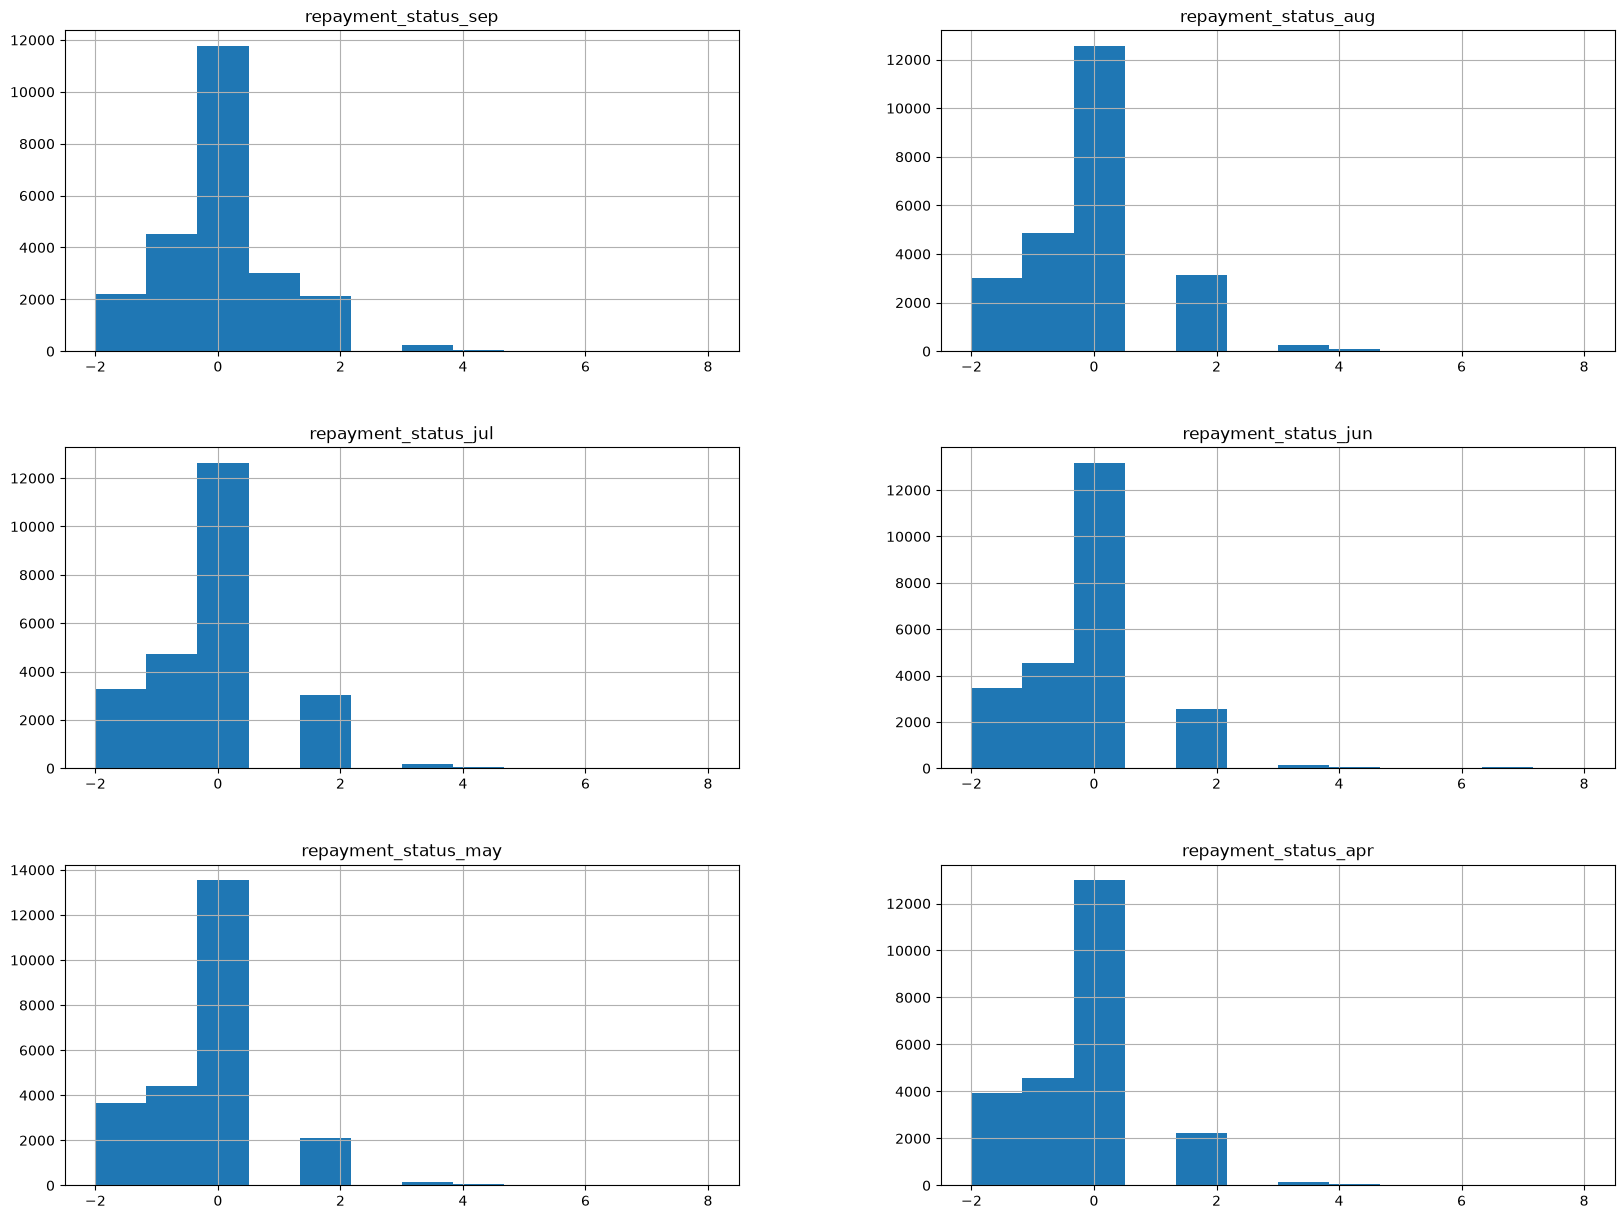

In [29]:
%matplotlib inline 
import matplotlib.pyplot as plt
training_data[repayment_columns].hist(bins=12, figsize=(20,15))
plt.show()

In [30]:
for column in repayment_columns:
    print(column, sorted(training_data[column].dropna().unique()))

repayment_status_sep [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
repayment_status_aug [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
repayment_status_jul [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
repayment_status_jun [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
repayment_status_may [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
repayment_status_apr [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


In [31]:
training_data[repayment_columns[0]].value_counts()

repayment_status_sep
 0    11781
-1     4527
 1     3000
-2     2198
 2     2138
 3      245
 4       58
 5       18
 8       16
 6       10
 7        9
Name: count, dtype: int64

In [32]:
training_data[repayment_columns[0]].value_counts(normalize=True).mul(100).round(2)

repayment_status_sep
 0    49.09
-1    18.86
 1    12.50
-2     9.16
 2     8.91
 3     1.02
 4     0.24
 5     0.08
 8     0.07
 6     0.04
 7     0.04
Name: proportion, dtype: float64

### Observation: September Repayment Status

- Code `0` is the most frequent repayment status, representing 11,781 customers or 49.09% of the training data.
- Codes `-1` and `-2` represent 18.86% and 9.16%, respectively.
- Although codes `0` and `-2` occur frequently in the dataset, their meanings are not clearly defined in the official documentation.
- Their high frequencies suggest that they are genuine operational categories rather than isolated data-entry errors.
- Therefore, codes `-2`, `-1`, and `0` will be retained as separate categories without assigning undocumented meanings.

In [33]:
total_customers = training_data.groupby(repayment_columns[0])["default_payment_next_month"].count()
total_default = training_data.groupby(repayment_columns[0])["default_payment_next_month"].sum()
total_default_rate = training_data.groupby(repayment_columns[0])["default_payment_next_month"].mean()

# Print results
print(f"Total Customers: {total_customers}")
print(f"Total Default: {total_default}")
print(f"Total Default Rate: {total_default_rate}")

Total Customers: repayment_status_sep
-2     2198
-1     4527
 0    11781
 1     3000
 2     2138
 3      245
 4       58
 5       18
 6       10
 7        9
 8       16
Name: default_payment_next_month, dtype: int64
Total Default: repayment_status_sep
-2     279
-1     753
 0    1508
 1    1031
 2    1483
 3     188
 4      38
 5       8
 6       6
 7       7
 8       8
Name: default_payment_next_month, dtype: int64
Total Default Rate: repayment_status_sep
-2    0.126934
-1    0.166335
 0    0.128003
 1    0.343667
 2    0.693639
 3    0.767347
 4    0.655172
 5    0.444444
 6    0.600000
 7    0.777778
 8    0.500000
Name: default_payment_next_month, dtype: float64


### Interpretation

- Repayment-status code `2` provides stronger evidence of high default risk.
- It has a default rate of 69.36%, based on 1,483 defaults among 2,138 customers.
- Code `8` has a 50% default rate, but it contains only 16 customers and 8 defaults.
- Therefore, the rate for code `8` is statistically unstable and should be interpreted cautiously.
- High percentages based on very small groups should not be compared directly with rates based on large groups.

In [34]:
results = training_data.groupby(column)["default_payment_next_month"].agg(
    total_customers="count",
    total_defaults="sum",
    default_rate="mean"
)
results

,total_customers,total_defaults,default_rate
repayment_status_apr,,,
-2,3942,778,0.197362
-1,4576,773,0.168925
0,13008,2465,0.189499
2,2230,1130,0.506726
3,149,93,0.624161
4,42,29,0.690476
5,8,5,0.625000
6,11,8,0.727273
7,33,27,0.818182


In [35]:
print("Customers in grouped results:", results["total_customers"].sum())
print("Customers in training data:", len(training_data))

print("\nDefaults in grouped results:", results["total_defaults"].sum())
print("Customers in training data:", y_train.sum())

Customers in grouped results: 24000
Customers in training data: 24000

Defaults in grouped results: 5309
Customers in training data: 5309


In [36]:
# April Repayment Status
result = training_data.groupby('repayment_status_apr')['default_payment_next_month'].agg(
    total_customers="count", 
    total_defaults="sum", 
    default_rate="mean"
)
print("Grouped customers:", result["total_customers"].sum())
print("Training customers:", len(training_data))

print("Grouped defaults:", result["total_defaults"].sum())
print(
    "Training defaults:",
    training_data["default_payment_next_month"].sum()
)

Grouped customers: 24000
Training customers: 24000
Grouped defaults: 5309
Training defaults: 5309


In [37]:
# Sanity check for all repayments
for columns in repayment_columns:
    monthly_results = training_data.groupby(columns)['default_payment_next_month'].agg(
        total_customers='count',
        total_defaults='sum',
        default_rate='mean'
    )
    print(f"\n{columns}")
    display(monthly_results)


repayment_status_sep


,total_customers,total_defaults,default_rate
repayment_status_sep,,,
-2,2198,279,0.126934
-1,4527,753,0.166335
0,11781,1508,0.128003
1,3000,1031,0.343667
2,2138,1483,0.693639
3,245,188,0.767347
4,58,38,0.655172
5,18,8,0.444444
6,10,6,0.600000



repayment_status_aug


,total_customers,total_defaults,default_rate
repayment_status_aug,,,
-2,3030,544,0.179538
-1,4845,774,0.159752
0,12573,2006,0.159548
1,25,5,0.200000
2,3145,1749,0.556121
3,254,162,0.637795
4,78,39,0.500000
5,21,13,0.619048
6,11,8,0.727273



repayment_status_jul


...

,total_customers,total_defaults,default_rate
repayment_status_jun,,,
-2,3477,646,0.185792
-1,4531,722,0.159347
0,13180,2433,0.184598
1,2,1,0.500000
2,2542,1338,0.526357
3,143,87,0.608392
4,53,34,0.641509
5,28,12,0.428571
6,3,1,0.333333



repayment_status_may


,total_customers,total_defaults,default_rate
repayment_status_may,,,
-2,3659,701,0.191582
-1,4417,736,0.166629
0,13560,2560,0.188791
2,2102,1148,0.546147
3,142,84,0.591549
4,65,37,0.569231
5,13,7,0.538462
6,3,3,1.000000
7,38,32,0.842105



repayment_status_apr


,total_customers,total_defaults,default_rate
repayment_status_apr,,,
-2,3942,778,0.197362
-1,4576,773,0.168925
0,13008,2465,0.189499
2,2230,1130,0.506726
3,149,93,0.624161
4,42,29,0.690476
5,8,5,0.625000
6,11,8,0.727273
7,33,27,0.818182
